# INTRODUCTION


> The major objective of this notebook is to build a model that can predict the median housing price in any district across California, given that we provide it with the required parameters.



The main objective of this notebook is to build a model that can predict the median housing price in any district across California, given the required parameters.

We'll be using the California housing prices dataset, which is based on the 1990 California census and contains various metrics for each district in the state. Since the dataset already includes the median housing price for each district and that's what we're predicting, this is a classic supervised regression task. Also, because the dataset isn't huge and no new data is arriving incrementally, we'll go with batch training.

# FETCHING AND ANALYZING THE DATA

> We'll start by loading the data and checking its structure and schema.



In [ ]:
import os
import tarfile
import urllib

DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
  os.makedirs(housing_path, exist_ok=True)
  tgz_path = os.path.join(housing_path, "housing.tgz")
  urllib.request.urlretrieve(housing_url, tgz_path)
  housing_tgz = tarfile.open(tgz_path)
  housing_tgz.extractall(path=housing_path)
  housing_tgz.close()

import pandas as pd
def load_housing_data(housing_path=HOUSING_PATH):
  csv_path = os.path.join(housing_path, "housing.csv")
  return pd.read_csv(csv_path)

In [ ]:
fetch_housing_data()
housing_data = load_housing_data()

/tmp/ipykernel_2657/987263091.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  housing_tgz.extractall(path=housing_path)


Now that the California housing dataset is loaded into housing_data, let's inspect its first five rows and then look at a short description of the data using the .info() method.


In [ ]:
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
housing_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


From the code output above, we observe that our dataset has 20,640 instances and 10 attributes: longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value, and ocean_proximity. However, total_bedrooms is missing values in roughly 207 instances. Every column except ocean_proximity holds float values; ocean_proximity shows up as an object type, which—since we loaded it from a CSV file—tells us it is a text attribute.





Furthermore, looking at the first five rows, the values in ocean_proximity repeat, suggesting it is categorical. Let's check the frequency of each category in ocean_proximity and then inspect a statistical summary of the numerical attributes.

In [ ]:
housing_data['ocean_proximity'].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [ ]:
housing_data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In order to visualize this data and to get a better feel of this data, let us now plot a histogram on this dataset using Matplotlib and the .hist() function.

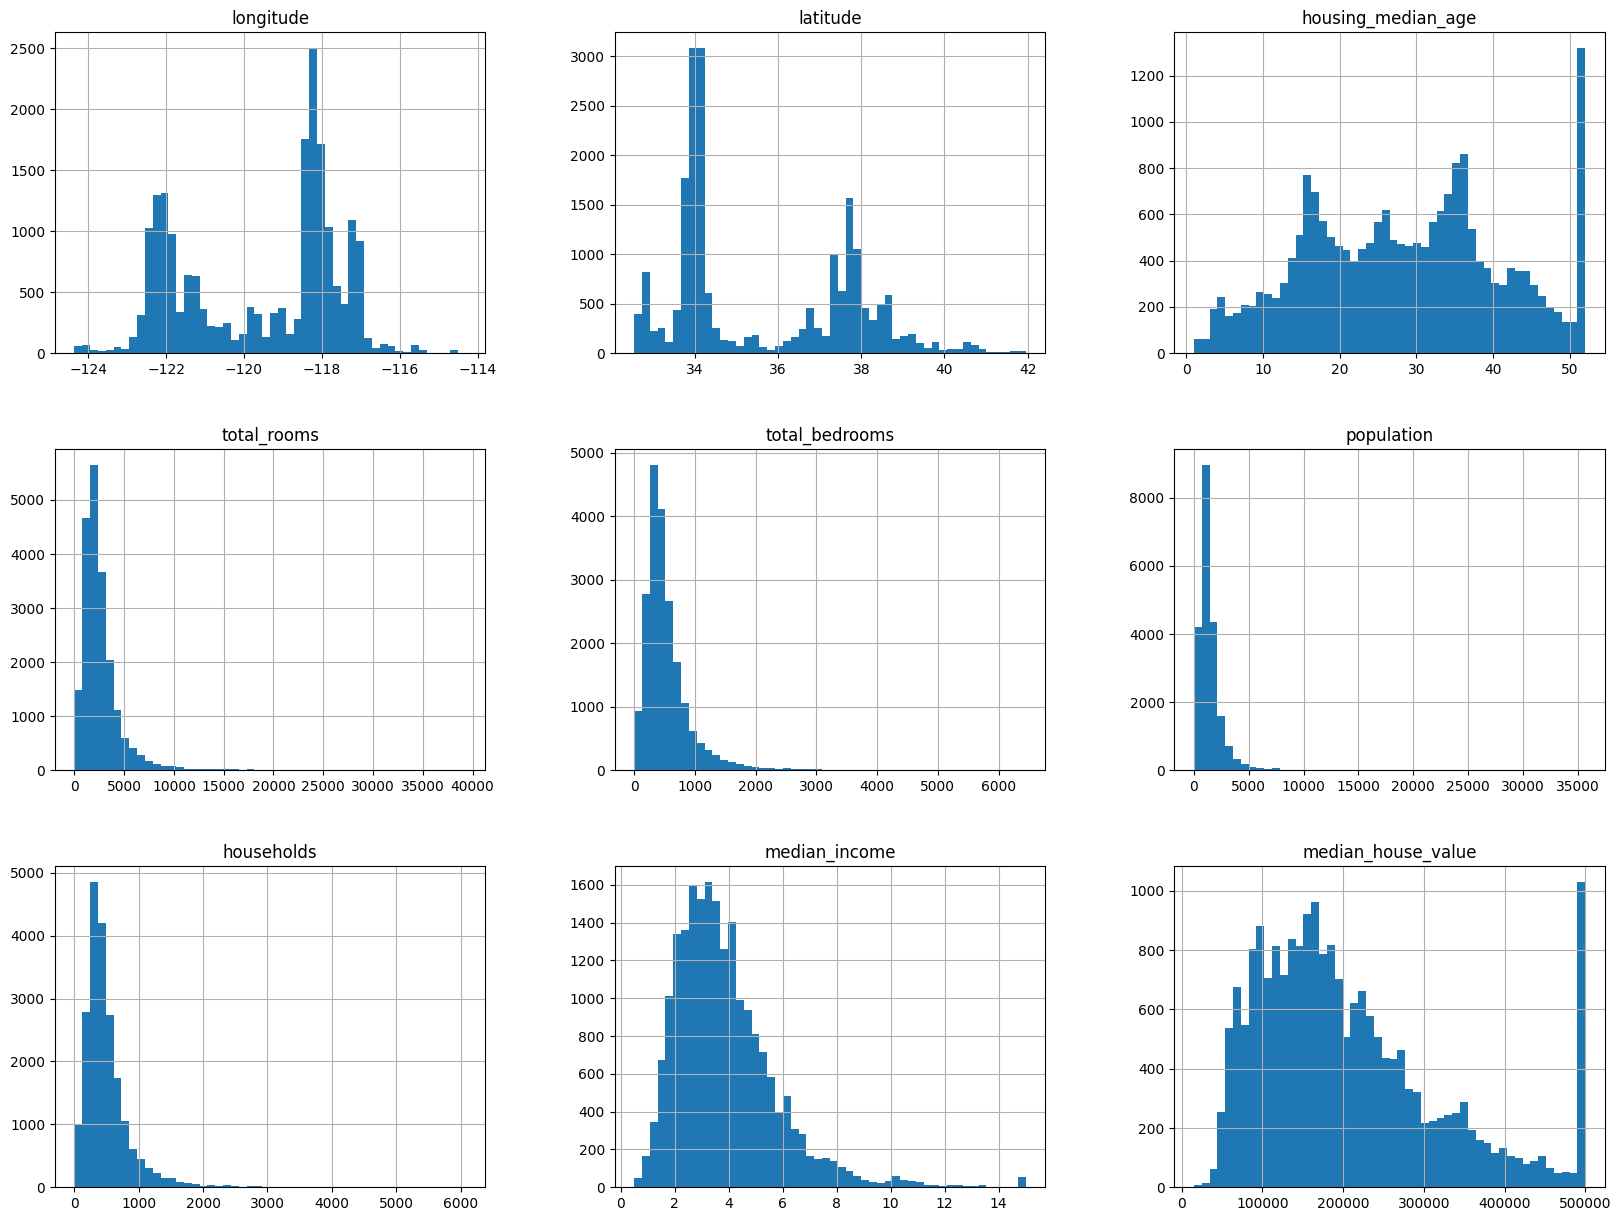

In [ ]:
import matplotlib.pyplot as plt
housing_data.hist(bins=50, figsize = (20, 15))
plt.show()

From the histograms above, we notice a few key things:


1.   The values in median_income are not expressed directly in US dollars—checking the dataset documentation shows they are scaled in units of 10,000 dollars (so  each unit represents $10,000).
2.   The attributes have very different scales.
1.   Many attributes are tail-heavy—meaning their distributions extend farther to one side rather than forming a bell curve—which can make learning harder for some models, so we'll look into transforming or normalizing them later on.











# SPLITTING INTO TRAIN - TEST SET


> Before we begin cleaning the data or training the model, we need to split the dataset into a training set used to train our model and a test set used later on to evaluate its performance.



In our housing dataset, we know from domain sources that median income plays a very important role in predicting median housing price. To make sure the training and test sets are representative, we use a stratified train-test split that divides the data into strata and then chooses the required number of samples from those strata so both sets stay representative. We begin by dividing median_income into 5 bins—seeing that most values lie between 1.5 and 6, while quite a few go beyond 6, which we must make sure not to ignore.

<Axes: >

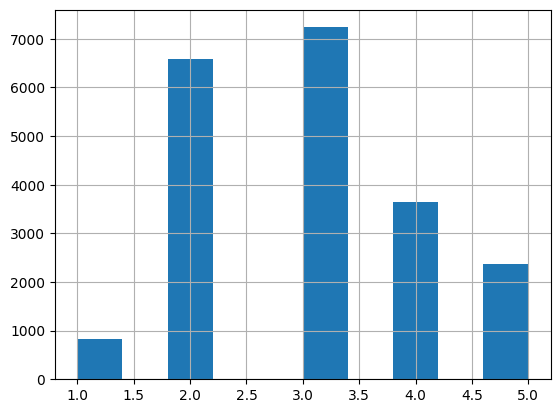

In [ ]:
import numpy as np
housing_data["income_category"] = pd.cut(housing_data["median_income"],
                                         bins = [0, 1.5, 3, 4.5, 6, np.inf],
                                         labels = [1,2,3,4,5])
housing_data["income_category"].hist()

In the code block above, we divided median_income into 5 categories and plotted a histogram. When choosing the number of categories, we need to make sure that we do not have too many strata and each stratum should be large enough. Now, we proceed with the stratified split using this income_category column.

In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits = 1, test_size = 0.2 ,random_state = 42)

for train_index, test_index in split.split(housing_data, housing_data["income_category"]):
  train_set = housing_data.loc[train_index]
  test_set = housing_data.loc[test_index]

Now that we have split the data into train and test sets, we drop the income_category attribute so that our dataset is back to its original state.

In [ ]:
for x in (train_set, test_set):
  x.drop("income_category", axis = 1, inplace = True)

# DISCOVER AND VISUALIZE THE DATA

> So far, we have taken a quick glance at the data and split it into a training set and a test set. Now let's dive deeper and explore the training set in more detail.



Before we continue, let's make a copy of the train set so that we can play around with it without hampering the original data.

In [ ]:
housing_data = train_set.copy()

Since our dataset involves geographical data let us begin by plotting a scatterplot of all the districts to visualize the data.

<Axes: xlabel='longitude', ylabel='latitude'>

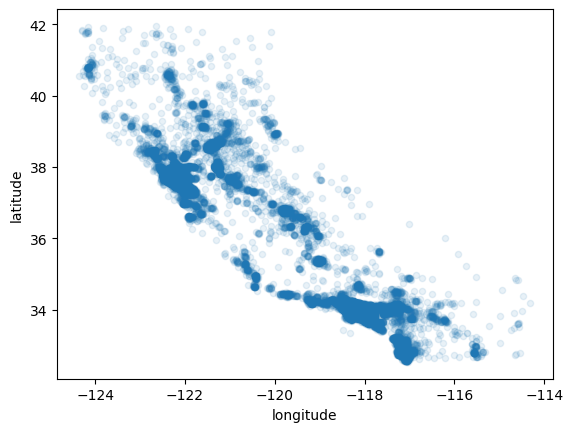

In [ ]:
housing_data.plot(kind = "scatter", x = "longitude", y ="latitude", alpha = 0.1)

You can clearly see the high-density areas, namely the Bay
Area and around Los Angeles and San Diego, plus a long line of fairly high density in
the Central Valley, in particular around Sacramento and Fresno. Now, let's dive a bit more into this and take a look at the housing prices, in the graph that we are going to be plotting now the size of the circle represents the population and the color of the circles represent the housing price.

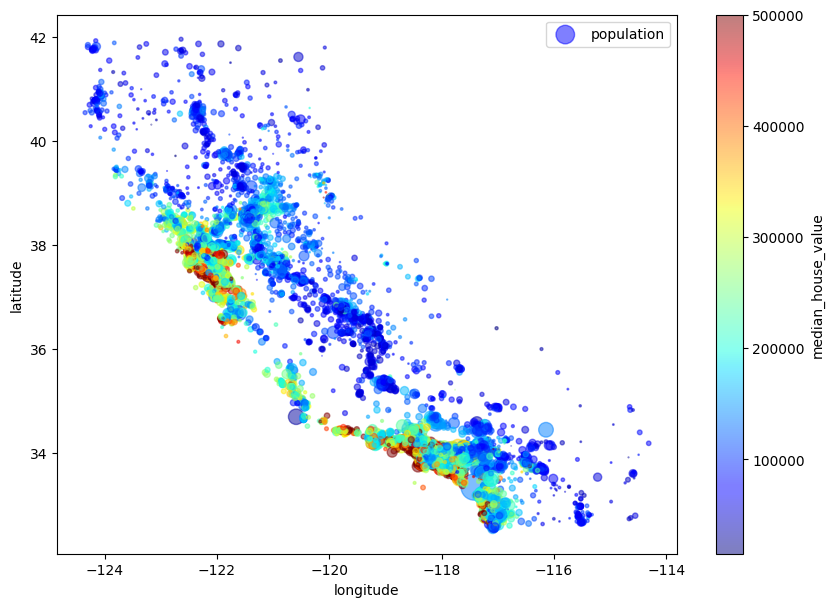

In [ ]:
housing_data.plot(kind = "scatter", x="longitude", y="latitude", alpha = 0.5,
                  s = housing_data["population"]/100, c = "median_house_value", label = "population", cmap = plt.get_cmap("jet"),
                  figsize = (10,7), colorbar = True,)
plt.legend()


The above scatter plot shows us that the median housing price is highly dependent on the population and the location as well. Let us move on and calculate the correlation factor between every numerical varaible using the correlation matrix. This will give us an idea on how much each attribute is dependent on the other one.

In [ ]:
corr_matrix = housing_data.corr(numeric_only = True)
corr_matrix["median_house_value"].sort_values(ascending = False)

,median_house_value
median_house_value,1.000000
median_income,0.687151
total_rooms,0.135140
housing_median_age,0.114146
households,0.064590
total_bedrooms,0.047781
population,-0.026882
longitude,-0.047466
latitude,-0.142673


The median_income attribute has the highest correlation factor with  the median_house_value this indicates that the house values increase as the median income of an area increases, the median_income can prove to be an important attribute for the prediction of the median_house_value so, let us proceed by plotting a scatter plot of these two attributes and take a look into the patterns and relations between this attributes.

<Axes: xlabel='median_income', ylabel='median_house_value'>

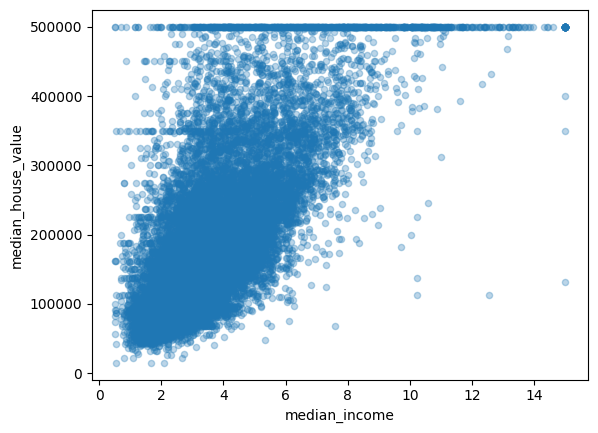

In [ ]:
housing_data.plot(kind="scatter", x="median_income", y="median_house_value", alpha = 0.3)

This scatter plot shows us that there is indeed a strong correlation between the median_income and the median_house_value and we can see that the graph has a clear upward trend along with a few quirks such as tright lines at 500000, 4500000 and 3500000.  Procceding further, let us try and experiment creating new attributes like number of rooms per household, number of bedrooms to rooms ratio and the population per household.

In [ ]:
housing_data["rooms_per_household"] = housing_data["total_rooms"]/housing_data["households"]
housing_data["bedrooms_per_room"] = housing_data["total_bedrooms"]/housing_data["total_rooms"]
housing_data["population_per_household"]= housing_data["population"]/housing_data["households"]
corr_matrix = housing_data.corr(numeric_only = True)
corr_matrix["median_house_value"].sort_values(ascending = False)

,median_house_value
median_house_value,1.000000
median_income,0.687151
rooms_per_household,0.146255
total_rooms,0.135140
housing_median_age,0.114146
households,0.064590
total_bedrooms,0.047781
population_per_household,-0.021991
population,-0.026882
longitude,-0.047466


From the values in the correlation matrix above we can say that the bedrooms_per_room attribute is negatively correlated with the median_house_value which implies that the houses that have a lower bedroom/room ratio tend to be more expensive further the rooms_per_household parameter is positively related to the median_house_value which indicates that the housing prices increases as the number of rooms per household increases, what we did about is called feature engineering and out of the three features that we have engineered two of them have shown to be useful in the prediction of the median housing price.

# CLEANING AND PREPARING THE DATA


> Before feeding the data into the model, we need to clean and prepare it—handling missing values, encoding categorical features, and scaling numerical ones—so the model runs efficiently and gives accurate results.



We begin by creating a copy of the test set and splitting the target(labels)  from the training set because we do not have to apply the same transformation to both the predictors and the target values.

In [ ]:
housing_data = test_set.drop(columns="median_house_value", axis = 1)
housing_labels = test_set["median_house_value"].copy()

Most machine learning models don't handle missing values well, so in the next few code blocks we'll focus on spotting those attributes and dealing with them.

When you run into missing data, you usually have three main options: drop the rows with missing values, drop the whole attribute, or fill in the gaps with a set value (like the mean or median, since both measure central tendency—though the median is safer when data is skewed).

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy = "median")
housing_num = housing_data.drop(columns="ocean_proximity", axis = 1)
imputer.fit(housing_num)
imputer.statistics_

array([-118.46  ,   34.22  ,   28.    , 2159.5   ,  442.    , 1172.5   ,
        416.    ,    3.5132])

In [ ]:
X = imputer.transform(housing_num)
housing_tr = pd.DataFrame(X, columns = housing_num.columns, index = housing_num.index)

We've filled in the missing values with each attribute's median. Now let's move on to handling the text and categorical attributes.

In [ ]:
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
housing_cat = housing_data[["ocean_proximity"]]
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot = housing_cat_1hot.toarray()

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
rooms_ix, bedrooms_ix, population_ix, households_ix = 3, 4, 5, 6
class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
 def __init__(self, add_bedrooms_per_room = True): # no *args or **kargs
  self.add_bedrooms_per_room = add_bedrooms_per_room
 def fit(self, X, y=None):
  return self # nothing else to do
 def transform(self, X):
  rooms_per_household = X[:, rooms_ix] / X[:, households_ix]
  population_per_household = X[:, population_ix] / X[:, households_ix]
  if self.add_bedrooms_per_room:
    bedrooms_per_room = X[:, bedrooms_ix] / X[:, rooms_ix]
    return np.c_[X, rooms_per_household, population_per_household,
    bedrooms_per_room]
  else:
    return np.c_[X, rooms_per_household, population_per_household]
    attr_adder = CombinedAttributesAdder(add_bedrooms_per_room=False)
    housing_extra_attribs = attr_adder.transform(housing.values)


Another important data prep step is feature scaling. ML models usually don't perform well when attributes are on very different scales, so we scale them to keep things balanced. Since we have a bunch of preprocessing steps to run in order, putting them into a pipeline makes the code much cleaner and easier to manage.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = "median")),
    ('attribs_adder', CombinedAttributesAdder()),
    ('std_scaler', StandardScaler())
])
housing_num_tr = num_pipeline.fit_transform(housing_num)

We already have a pipeline for the numerical attributes, and we've handled the categorical ones on their own up to this point. Now let's bring both together into one combined preprocessing pipeline.

In [ ]:
from sklearn.compose import ColumnTransformer
num_attribs = list(housing_num)
cat_attribs = ["ocean_proximity"]

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(), cat_attribs)
])
housing_data_cleaned = full_pipeline.fit_transform(housing_data)

# SELECT AND TRAIN A MODEL

> We've split the data into train and test sets, explored the data, spotted important attributes, engineered a few new features, and built pipelines to clean and prep our data. Now let's move on and train our model.



Let us begin with a linear regression model.

In [ ]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(housing_data_cleaned, housing_labels)
#now let us look at the value this model predicts for the first 5 instances of our dataset and compare it with the actual value
data1 = housing_data.iloc[:5]
label1 = housing_labels.iloc[:5]
data1_prepared = full_pipeline.transform(data1)
lin_reg.predict(data1_prepared)

array([421732.95505945, 289987.27320545, 240255.16335231, 189385.5513129 ,
       264249.1702114 ])

In [ ]:
list(label1)

[500001.0, 162500.0, 204600.0, 159700.0, 184000.0]

We have the linear regression model's predictions alongside the actual target values above. Just looking at them, the predictions aren't very accurate—so let's measure the error and calculate the RMSE.


In [ ]:
from sklearn.metrics import mean_squared_error
housing_data_predictions = lin_reg.predict(housing_data_cleaned)
lin_mse = mean_squared_error(housing_labels, housing_data_predictions)
lin_rmse = np.sqrt(lin_mse)
lin_rmse

np.float64(66787.70814784677)

This clearly isn't a great result—it points to the model underfitting the data. Usually that means either the features aren't informative enough or the model isn't flexible enough to capture the patterns. Let's try a more expressive model: a Decision Tree Regressor.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
tree_reg = DecisionTreeRegressor()
tree_reg.fit(housing_data_cleaned, housing_labels)
housing_data_predictions = tree_reg.predict(housing_data_cleaned)
tree_mse = mean_squared_error(housing_labels, housing_data_predictions)
tree_rmse = np.sqrt(tree_mse)
tree_rmse

np.float64(0.0)

A 0 error. Zero error doesn't always mean the model is predicting everything accurately—it can also mean the Decision Tree is severely overfitting the training data. Let's check this with cross-validation.

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(tree_reg, housing_data_cleaned, housing_labels, scoring = "neg_mean_squared_error", cv = 10)
tree_rmse_scores = np.sqrt(-scores)

In [ ]:
def display_scores(scores):
  print("Scores", scores)
  print("Mean", scores.mean())
  print("Standard deviation", scores.std())
display_scores(tree_rmse_scores)

Scores [73597.65471614 81846.44928222 76379.32101042 73641.28491633
 70259.17766071 66019.04743889 74985.62221216 77150.8539702
 68697.24145161 79342.45491522]
Mean 74191.91075738998
Standard deviation 4608.686969699736


Let's run cross-validation on the linear regression model too.

In [ ]:
scores = cross_val_score(lin_reg, housing_data_cleaned, housing_labels, scoring = "neg_mean_squared_error", cv = 10)
lin_rmse_scores = np.sqrt(-scores)
display_scores(lin_rmse_scores)

Scores [66830.21497764 73595.46286068 67888.5957665  69274.18198153
 66475.99624101 66144.88036095 64702.02705501 65639.32837098
 67105.20129799 67421.10791841]
Mean 67507.69968307031
Standard deviation 2350.301882873345


From the last two code blocks, we can see that the decision tree overfits the data so badly that it struggles to generalize—ending up worse than linear regression. Let's try one more model: a Random Forest Regressor.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
forest_reg = RandomForestRegressor()
forest_reg.fit(housing_data_cleaned, housing_labels)
scores = cross_val_score(forest_reg, housing_data_cleaned, housing_labels, scoring = "neg_mean_squared_error", cv = 10)
forest_rmse_scores = np.sqrt(-scores)
display_scores(forest_rmse_scores)

Scores [52985.30584723 56594.17597147 52001.69706728 50729.54263845
 50619.38009657 52513.66322349 52972.31865448 54727.44264711
 52527.76454872 59781.55507433]
Mean 53545.28457691269
Standard deviation 2668.2905388723893


The RandomForestRegressor looks much more promising. Even though it still overfits the training data a bit, the overall results are much better.

# FINE TUNING MODEL









We'll fine-tune our Random Forest model using Grid Search to find a better set of hyperparameters.

In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = [
 {'n_estimators': [3, 10, 30], 'max_features': [2, 4, 6, 8]},
 {'bootstrap': [False], 'n_estimators': [3, 10], 'max_features': [2, 3, 4]},
 ]
forest_reg = RandomForestRegressor()
grid_search = GridSearchCV(forest_reg, param_grid, cv=5,
 scoring='neg_mean_squared_error',
return_train_score=True)
grid_search.fit(housing_data_cleaned, housing_labels)
grid_search.best_estimator_

RandomForestRegressor(max_features=4, n_estimators=30)

After running Grid Search, the best hyperparameters we found are max_features=4 and n_estimators=30.

# EVALUATING THE MODEL ON THE TEST SET


> We've cleaned the data, trained a few different models, picked the strongest candidate, and tuned its hyperparameters. Now it's time to see how the final model actually performs on the test set.



In [ ]:
final_model = grid_search.best_estimator_
x_test = test_set.drop("median_house_value", axis = 1)
y_test = test_set["median_house_value"].copy()
x_test_cleaned = full_pipeline.transform(x_test)
final_predictions = final_model.predict(x_test_cleaned)
final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)
#calculating a 95% confidence interval for the error
from scipy import stats
confidence = 0.95
squared_errors = (final_predictions - y_test) ** 2
np.sqrt(stats.t.interval(confidence, len(squared_errors) - 1,
                        loc=squared_errors.mean(),
                        scale=stats.sem(squared_errors)))

array([19987.25454835, 21622.22288827])

On the test set, the 95% confidence interval for the RMSE sits right around $19,987 to $21,622. That gives us a pretty solid sense of how closely our tuned Random Forest model predicts unseen median_house_value data—and it lines up nicely with what we saw during cross-validation without a dramatic drop-off.

# CONCLUSION

We started by fetching and exploring the California housing dataset, splitting it into training and test sets, and analyzing the features before building out the preprocessing pipelines. Missing values were imputed with the median, numerical features were scaled, and categorical features like ocean_proximity were one-hot encoded and combined inside a single ColumnTransformer pipeline.   
When we moved to modeling, Linear Regression underfit the data, while a Decision Tree Regressor overfit heavily and generalized poorly. Random Forest proved much stronger, so we fine-tuned it with Grid Search (max_features=4 and n_estimators=30) and checked the final model on the held-out test set, landing on a 95% confidence interval of roughly $19,987 to $21,622 for the error.   